In [2]:
%pip install opencv-python numpy matplotlib scikit-image pandas

Note: you may need to restart the kernel to use updated packages.


In [3]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from skimage.metrics import structural_similarity

print("OpenCV:", cv2.__version__)
print("NumPy:", np.__version__)
print("All libraries imported successfully!")

OpenCV: 5.0.0
NumPy: 2.3.5
All libraries imported successfully!


Number of images found: 10


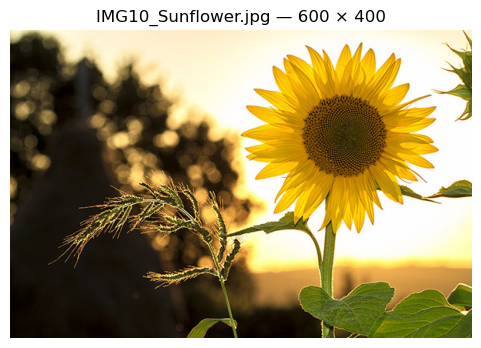

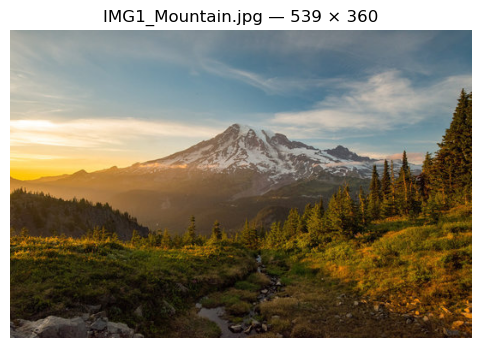

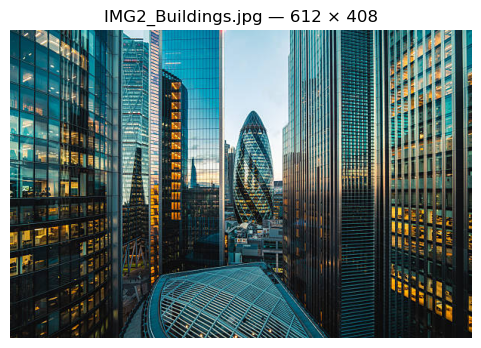

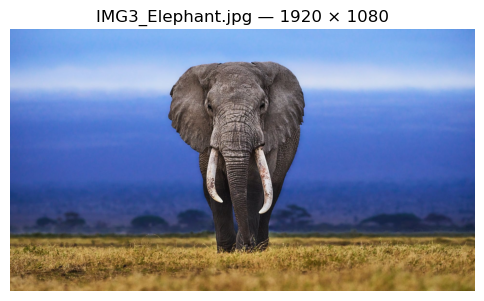

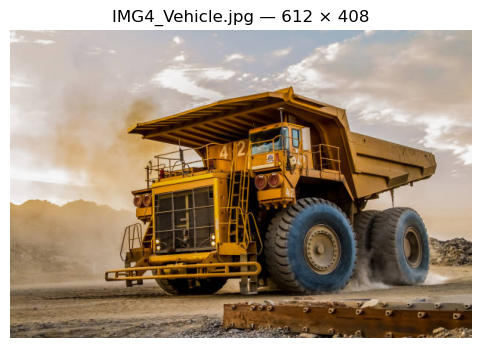

In [4]:
import os
import cv2
import matplotlib.pyplot as plt

# Update this path to match your folder location
IMAGE_DIR = r"C:\Users\USER\Desktop\7th SEM\DIP\Project\Images\Original"

# Supported image formats
valid_extensions = (".jpg", ".jpeg", ".png", ".bmp")

# Find image files
image_files = sorted([
    f for f in os.listdir(IMAGE_DIR)
    if f.lower().endswith(valid_extensions)
])

print("Number of images found:", len(image_files))

if len(image_files) == 0:
    print("No images found. Check your folder path.")
else:
    for filename in image_files[:5]:
        path = os.path.join(IMAGE_DIR, filename)

        image = cv2.imread(path)

        if image is None:
            print("Could not load:", filename)
            continue

        # Convert BGR to RGB for correct display
        image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        plt.figure(figsize=(6, 4))
        plt.imshow(image_rgb)
        plt.title(f"{filename} — {image.shape[1]} × {image.shape[0]}")
        plt.axis("off")
        plt.show()

Original images found: 10
Low-light dataset generated successfully!


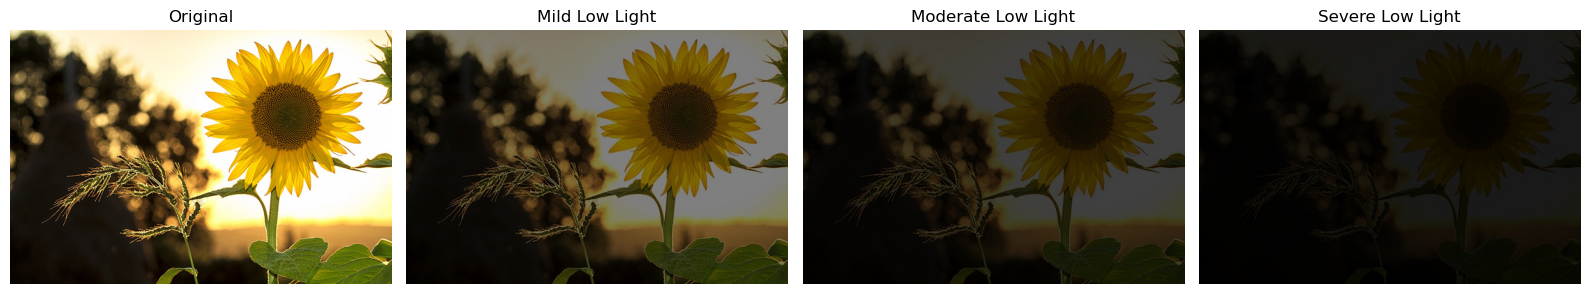

Output directory: C:\Users\USER\Desktop\7th SEM\DIP\Project\Images\Low_Light


In [5]:
import os
import cv2
import matplotlib.pyplot as plt

# Project directories
IMAGE_DIR = r"C:\Users\USER\Desktop\7th SEM\DIP\Project\Images\Original"

OUTPUT_DIR = r"C:\Users\USER\Desktop\7th SEM\DIP\Project\Images\Low_Light"

# Brightness reduction factors
brightness_levels = {
    "Mild": 0.50,
    "Moderate": 0.25,
    "Severe": 0.10
}

# Create output folders
for level in brightness_levels:
    os.makedirs(os.path.join(OUTPUT_DIR, level), exist_ok=True)

# Load image filenames
valid_extensions = (".jpg", ".jpeg", ".png", ".bmp")

image_files = sorted([
    f for f in os.listdir(IMAGE_DIR)
    if f.lower().endswith(valid_extensions)
])

print("Original images found:", len(image_files))

# Generate low-light images
for filename in image_files:
    image_path = os.path.join(IMAGE_DIR, filename)
    image = cv2.imread(image_path)

    if image is None:
        print("Skipping unreadable image:", filename)
        continue

    for level, factor in brightness_levels.items():
        # Reduce pixel intensity
        low_light = cv2.convertScaleAbs(image, alpha=factor, beta=0)

        output_path = os.path.join(OUTPUT_DIR, level, filename)
        cv2.imwrite(output_path, low_light)

print("Low-light dataset generated successfully!")

# Display one example at all brightness levels
example_name = image_files[0]
original = cv2.imread(os.path.join(IMAGE_DIR, example_name))
original = cv2.cvtColor(original, cv2.COLOR_BGR2RGB)

fig, axes = plt.subplots(1, 4, figsize=(16, 5))

axes[0].imshow(original)
axes[0].set_title("Original")

for ax, level in zip(axes[1:], brightness_levels):
    path = os.path.join(OUTPUT_DIR, level, example_name)
    img = cv2.imread(path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    ax.imshow(img)
    ax.set_title(level + " Low Light")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Output directory:", OUTPUT_DIR)

In [6]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import time

# ==========================================
# 1. PROJECT PATHS
# ==========================================

PROJECT_DIR = r"C:\Users\USER\Desktop\7th SEM\DIP\Project"

ORIGINAL_DIR = os.path.join(PROJECT_DIR, "Images", "Original")
LOW_LIGHT_DIR = os.path.join(PROJECT_DIR, "Images", "Low_Light")
RESULTS_DIR = os.path.join(PROJECT_DIR, "Results", "Enhanced")

os.makedirs(RESULTS_DIR, exist_ok=True)


# ==========================================
# 2. HELPER FUNCTIONS
# ==========================================

def adjust_gamma(image, gamma):
    """Apply gamma correction using a lookup table."""
    gamma = max(float(gamma), 0.01)

    table = np.array([
        ((i / 255.0) ** gamma) * 255
        for i in range(256)
    ]).clip(0, 255).astype(np.uint8)

    return cv2.LUT(image, table)


def apply_he(image):
    """Apply histogram equalization to the luminance channel."""
    lab = cv2.cvtColor(image, cv2.COLOR_BGR2LAB)

    l_channel, a_channel, b_channel = cv2.split(lab)

    enhanced_l = cv2.equalizeHist(l_channel)

    enhanced_lab = cv2.merge(
        [enhanced_l, a_channel, b_channel]
    )

    return cv2.cvtColor(enhanced_lab, cv2.COLOR_LAB2BGR)


def apply_clahe(image, clip_limit=2.0, tile_grid=(8, 8)):
    """Apply CLAHE to the luminance channel."""
    lab = cv2.cvtColor(image, cv2.COLOR_BGR2LAB)

    l_channel, a_channel, b_channel = cv2.split(lab)

    clahe = cv2.createCLAHE(
        clipLimit=clip_limit,
        tileGridSize=tile_grid
    )

    enhanced_l = clahe.apply(l_channel)

    enhanced_lab = cv2.merge(
        [enhanced_l, a_channel, b_channel]
    )

    return cv2.cvtColor(enhanced_lab, cv2.COLOR_LAB2BGR)


def image_brightness_contrast(image):
    """Measure mean luminance and luminance standard deviation."""
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    brightness = float(np.mean(gray))
    contrast = float(np.std(gray))

    return brightness, contrast


# ==========================================
# 3. PROPOSED BCGAE METHOD
# ==========================================

def apply_bcgae(image):
    """
    Brightness and Contrast Guided Adaptive Enhancement.

    Gamma and CLAHE parameters are selected using
    measured brightness and contrast.

    These are initial heuristic rules and will need
    evaluation on the experimental dataset.
    """

    brightness, contrast = image_brightness_contrast(image)

    # Select gamma based on image brightness.
    if brightness < 60:
        gamma = 0.45
    elif brightness < 100:
        gamma = 0.60
    else:
        gamma = 0.75

    # Select CLAHE clip limit based on image contrast.
    if contrast < 35:
        clip_limit = 3.0
    elif contrast < 60:
        clip_limit = 2.0
    else:
        clip_limit = 1.5

    # First adjust brightness, then enhance local contrast.
    gamma_corrected = adjust_gamma(image, gamma)

    enhanced = apply_clahe(
        gamma_corrected,
        clip_limit=clip_limit
    )

    return enhanced


# ==========================================
# 4. DEFINE THE FIVE METHODS
# ==========================================

def get_enhanced_images(image):
    """Run all five enhancement methods on one image."""

    # Method 1: Histogram Equalization
    he = apply_he(image)

    # Method 2: Gamma Correction
    gamma = adjust_gamma(image, 0.60)

    # Method 3: CLAHE
    clahe = apply_clahe(image, clip_limit=2.0)

    # Method 4: Fixed Gamma + CLAHE
    fixed_gamma = adjust_gamma(image, 0.60)
    hybrid = apply_clahe(fixed_gamma, clip_limit=2.0)

    # Method 5: Proposed BCGAE
    bcgae = apply_bcgae(image)

    return {
        "HE": he,
        "Gamma": gamma,
        "CLAHE": clahe,
        "Fixed_Gamma_CLAHE": hybrid,
        "BCGAE": bcgae
    }


print("All five enhancement methods defined successfully.")

All five enhancement methods defined successfully.


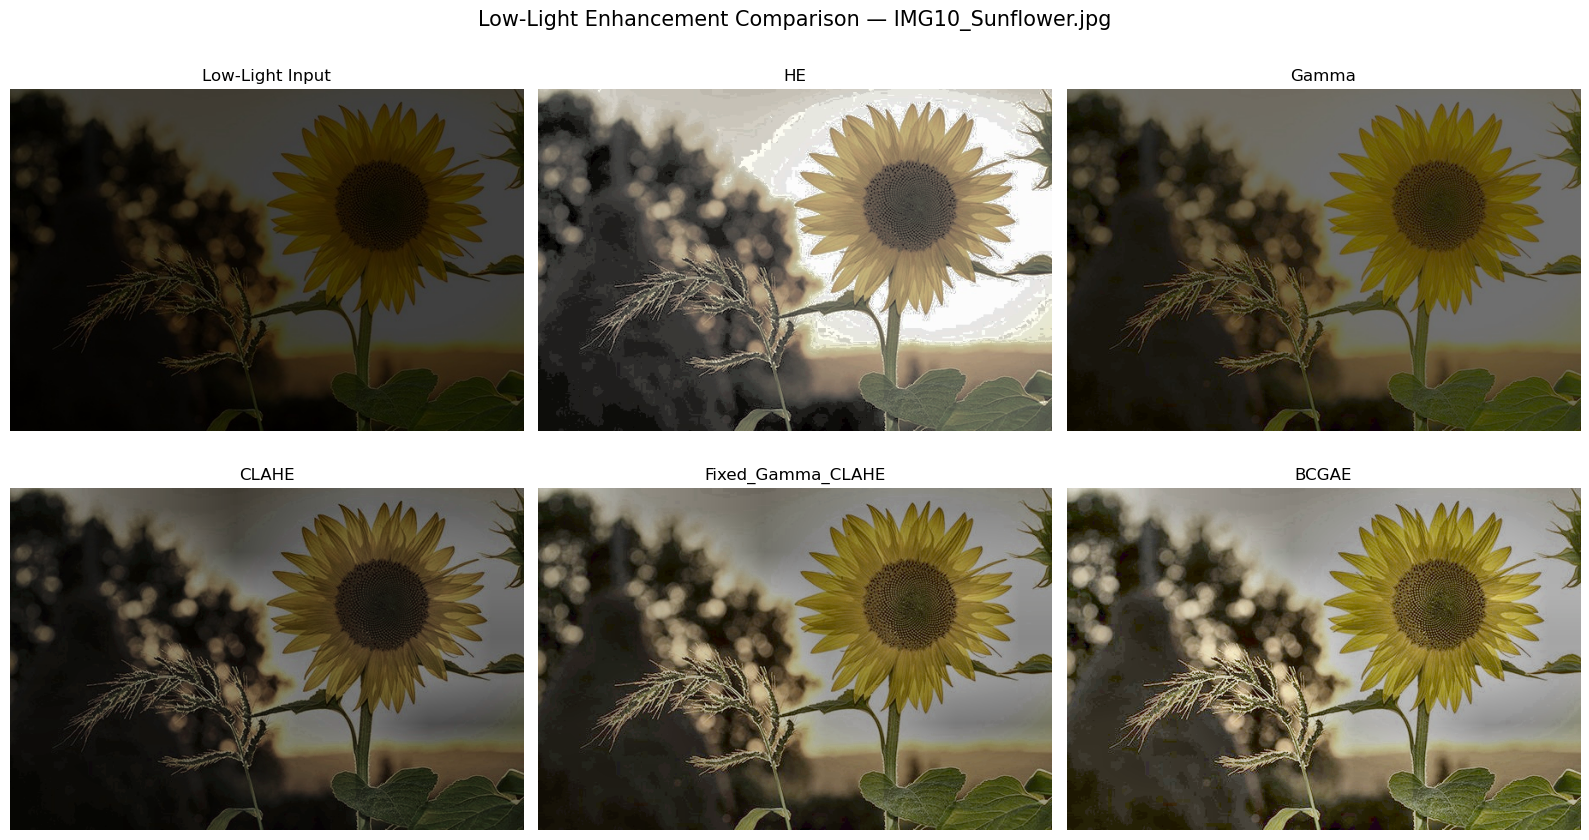

In [7]:
# ==========================================
# VISUAL COMPARISON
# ==========================================

LEVEL = "Moderate"

input_dir = os.path.join(LOW_LIGHT_DIR, LEVEL)

image_files = sorted([
    f for f in os.listdir(input_dir)
    if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp"))
])

if not image_files:
    raise FileNotFoundError(
        f"No images found in {input_dir}. Check the folder path."
    )

# Select the first image
filename = image_files[0]
image_path = os.path.join(input_dir, filename)

input_image = cv2.imread(image_path)

if input_image is None:
    raise ValueError(f"Could not read image: {image_path}")

# Run all enhancement methods
enhanced_images = get_enhanced_images(input_image)

# Display the original input and all five results
display_images = {
    "Low-Light Input": input_image,
    **enhanced_images
}

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for ax, (title, img) in zip(axes, display_images.items()):
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    ax.imshow(img_rgb)
    ax.set_title(title)
    ax.axis("off")

plt.suptitle(
    f"Low-Light Enhancement Comparison — {filename}",
    fontsize=15
)

plt.tight_layout()
plt.show()

In [8]:
# ==========================================
# PROCESS ALL 30 LOW-LIGHT IMAGES
# ==========================================

levels = ["Mild", "Moderate", "Severe"]

method_names = [
    "HE",
    "Gamma",
    "CLAHE",
    "Fixed_Gamma_CLAHE",
    "BCGAE"
]

processing_records = []

for level in levels:

    input_dir = os.path.join(LOW_LIGHT_DIR, level)

    if not os.path.isdir(input_dir):
        print(f"Skipping missing folder: {input_dir}")
        continue

    files = sorted([
        f for f in os.listdir(input_dir)
        if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp"))
    ])

    for filename in files:

        image_path = os.path.join(input_dir, filename)
        image = cv2.imread(image_path)

        if image is None:
            print("Skipping unreadable image:", image_path)
            continue

        # Time the complete set of methods on this image.
        start_time = time.perf_counter()

        outputs = get_enhanced_images(image)

        elapsed = time.perf_counter() - start_time

        # Save every enhanced output.
        for method, enhanced in outputs.items():

            method_dir = os.path.join(
                RESULTS_DIR, level, method
            )

            os.makedirs(method_dir, exist_ok=True)

            output_path = os.path.join(
                method_dir, filename
            )

            cv2.imwrite(output_path, enhanced)

            processing_records.append({
                "Level": level,
                "Image": filename,
                "Method": method,
                "Output_Path": output_path
            })

print("Processing completed!")
print("Total enhanced outputs:", len(processing_records))

processing_df = pd.DataFrame(processing_records)
display(processing_df.head(10))

print("Results saved to:", RESULTS_DIR)

Processing completed!
Total enhanced outputs: 150


,Level,Image,Method,Output_Path
0,Mild,IMG10_Sunflower.jpg,HE,C:\Users\USER\Desktop\7th SEM\DIP\Project\Resu...
1,Mild,IMG10_Sunflower.jpg,Gamma,C:\Users\USER\Desktop\7th SEM\DIP\Project\Resu...
2,Mild,IMG10_Sunflower.jpg,CLAHE,C:\Users\USER\Desktop\7th SEM\DIP\Project\Resu...
3,Mild,IMG10_Sunflower.jpg,Fixed_Gamma_CLAHE,C:\Users\USER\Desktop\7th SEM\DIP\Project\Resu...
4,Mild,IMG10_Sunflower.jpg,BCGAE,C:\Users\USER\Desktop\7th SEM\DIP\Project\Resu...
5,Mild,IMG1_Mountain.jpg,HE,C:\Users\USER\Desktop\7th SEM\DIP\Project\Resu...
6,Mild,IMG1_Mountain.jpg,Gamma,C:\Users\USER\Desktop\7th SEM\DIP\Project\Resu...
7,Mild,IMG1_Mountain.jpg,CLAHE,C:\Users\USER\Desktop\7th SEM\DIP\Project\Resu...
8,Mild,IMG1_Mountain.jpg,Fixed_Gamma_CLAHE,C:\Users\USER\Desktop\7th SEM\DIP\Project\Resu...
9,Mild,IMG1_Mountain.jpg,BCGAE,C:\Users\USER\Desktop\7th SEM\DIP\Project\Resu...


Results saved to: C:\Users\USER\Desktop\7th SEM\DIP\Project\Results\Enhanced


In [19]:
def apply_bcgae(image):
    """
    Brightness and Contrast Guided Adaptive Enhancement (BCGAE).

    Adaptive gamma correction followed by CLAHE.
    This is a heuristic variant that must be evaluated
    against the existing implementation.
    """

    brightness, contrast = image_brightness_contrast(image)

    # Stronger brightening for darker images
    if brightness < 40:
        gamma = 0.25
    elif brightness < 60:
        gamma = 0.35
    elif brightness < 90:
        gamma = 0.50
    elif brightness < 120:
        gamma = 0.65
    else:
        gamma = 0.80

    # Adaptive local contrast enhancement
    if contrast < 25:
        clip_limit = 3.0
    elif contrast < 45:
        clip_limit = 2.5
    else:
        clip_limit = 2.0

    gamma_corrected = adjust_gamma(image, gamma)

    enhanced = apply_clahe(
        gamma_corrected,
        clip_limit=clip_limit
    )

    return enhanced

print("Updated BCGAE function defined.")

Updated BCGAE function defined.


In [20]:
import os
import cv2
import numpy as np
import pandas as pd
import time

from skimage.metrics import (
    mean_squared_error,
    peak_signal_noise_ratio,
    structural_similarity
)

# ==========================================
# PATHS
# ==========================================

PROJECT_DIR = r"C:\Users\USER\Desktop\7th SEM\DIP\Project"

ORIGINAL_DIR = os.path.join(
    PROJECT_DIR, "Images", "Original"
)

LOW_LIGHT_DIR = os.path.join(
    PROJECT_DIR, "Images", "Low_Light"
)

RESULTS_DIR = os.path.join(
    PROJECT_DIR, "Results", "Enhanced"
)

LEVELS = ["Mild", "Moderate", "Severe"]

METHODS = [
    "HE",
    "Gamma",
    "CLAHE",
    "Fixed_Gamma_CLAHE",
    "BCGAE"
]


# ==========================================
# HELPER FUNCTIONS
# ==========================================

def calculate_entropy(image):
    """Calculate grayscale Shannon entropy."""
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    histogram = cv2.calcHist(
        [gray], [0], None, [256], [0, 256]
    ).ravel()

    probabilities = histogram / histogram.sum()
    probabilities = probabilities[probabilities > 0]

    return float(-np.sum(probabilities * np.log2(probabilities)))


def calculate_contrast(image):
    """Calculate grayscale intensity standard deviation."""
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    return float(np.std(gray))


# ==========================================
# EVALUATE ENHANCED IMAGES
# ==========================================

records = []

for level in LEVELS:

    for method in METHODS:

        method_dir = os.path.join(
            RESULTS_DIR, level, method
        )

        if not os.path.isdir(method_dir):
            print("Missing folder:", method_dir)
            continue

        image_files = sorted([
            f for f in os.listdir(method_dir)
            if f.lower().endswith(
                (".jpg", ".jpeg", ".png", ".bmp")
            )
        ])

        for filename in image_files:

            enhanced_path = os.path.join(
                method_dir, filename
            )

            original_path = os.path.join(
                ORIGINAL_DIR, filename
            )

            enhanced = cv2.imread(enhanced_path)
            original = cv2.imread(original_path)

            if enhanced is None or original is None:
                print("Skipping unreadable image:", filename)
                continue

            # Ensure matching dimensions.
            if enhanced.shape != original.shape:
                print("Dimension mismatch:", filename)
                continue

            original_gray = cv2.cvtColor(
                original, cv2.COLOR_BGR2GRAY
            )

            enhanced_gray = cv2.cvtColor(
                enhanced, cv2.COLOR_BGR2GRAY
            )

            mse = mean_squared_error(
                original_gray, enhanced_gray
            )

            psnr = peak_signal_noise_ratio(
                original_gray,
                enhanced_gray,
                data_range=255
            )

            ssim = structural_similarity(
                original_gray,
                enhanced_gray,
                data_range=255
            )

            entropy = calculate_entropy(enhanced)
            contrast = calculate_contrast(enhanced)

            records.append({
                "Level": level,
                "Method": method,
                "Image": filename,
                "MSE": mse,
                "PSNR_dB": psnr,
                "SSIM": ssim,
                "Entropy": entropy,
                "Contrast": contrast
            })


# ==========================================
# CREATE RESULTS TABLE
# ==========================================

metrics_df = pd.DataFrame(records)

if metrics_df.empty:
    print("No results found. Please verify the folder paths.")
else:
    print("Evaluation completed!")
    print("Total evaluated images:", len(metrics_df))

    display(metrics_df.head(10))

    # Save individual measurements.
    csv_path = os.path.join(
        PROJECT_DIR, "Results", "evaluation_results.csv"
    )

    os.makedirs(os.path.dirname(csv_path), exist_ok=True)

    metrics_df.to_csv(csv_path, index=False)

    print("\nResults saved to:", csv_path)

Evaluation completed!
Total evaluated images: 150


,Level,Method,Image,MSE,PSNR_dB,SSIM,Entropy,Contrast
0,Mild,HE,IMG10_Sunflower.jpg,569.267587,20.577639,0.810714,7.576632,72.908072
1,Mild,HE,IMG1_Mountain.jpg,659.948794,19.935701,0.923464,7.953758,71.712317
2,Mild,HE,IMG2_Buildings.jpg,1631.826237,16.004064,0.845371,7.923673,70.865246
3,Mild,HE,IMG3_Elephant.jpg,759.067441,19.328000,0.879440,7.848472,72.078886
4,Mild,HE,IMG4_Vehicle.jpg,414.725803,21.953193,0.896367,7.867797,73.510354
5,Mild,HE,IMG5_Crowd.jpg,1377.056286,16.741287,0.836629,7.942986,71.538106
6,Mild,HE,IMG6_Portrait.jpg,1610.133786,16.062184,0.817134,6.740767,72.297245
7,Mild,HE,IMG7_Road.jpg,4220.873236,11.876781,0.606002,7.801599,70.438681
8,Mild,HE,IMG8_Room.jpg,695.516561,19.707729,0.882028,7.845159,72.646335
9,Mild,HE,IMG9_Sea.jpg,522.504334,20.949905,0.905240,7.966775,71.818018



Results saved to: C:\Users\USER\Desktop\7th SEM\DIP\Project\Results\evaluation_results.csv


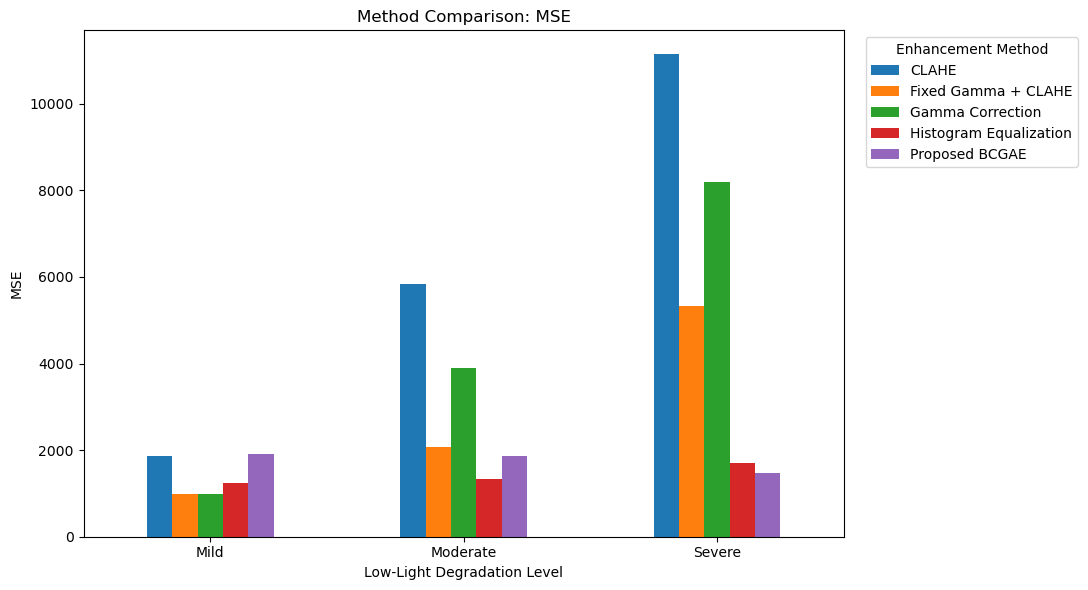

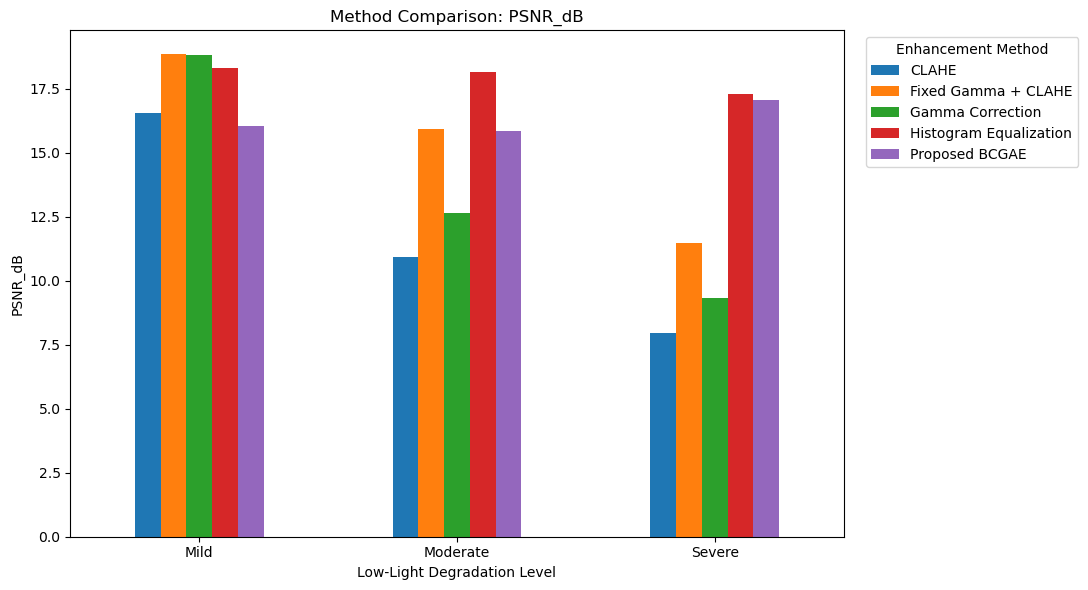

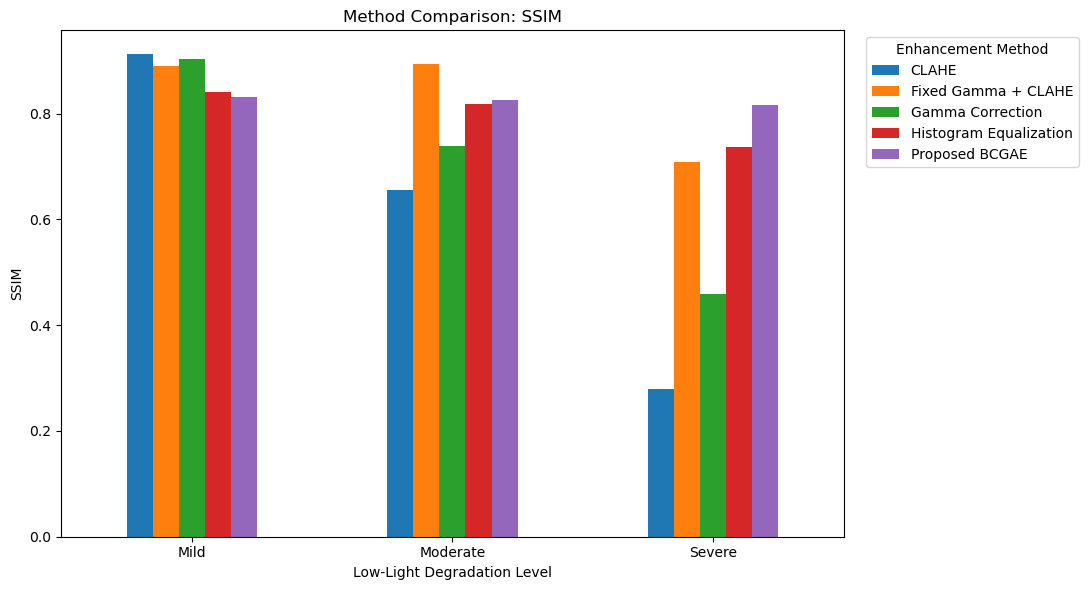

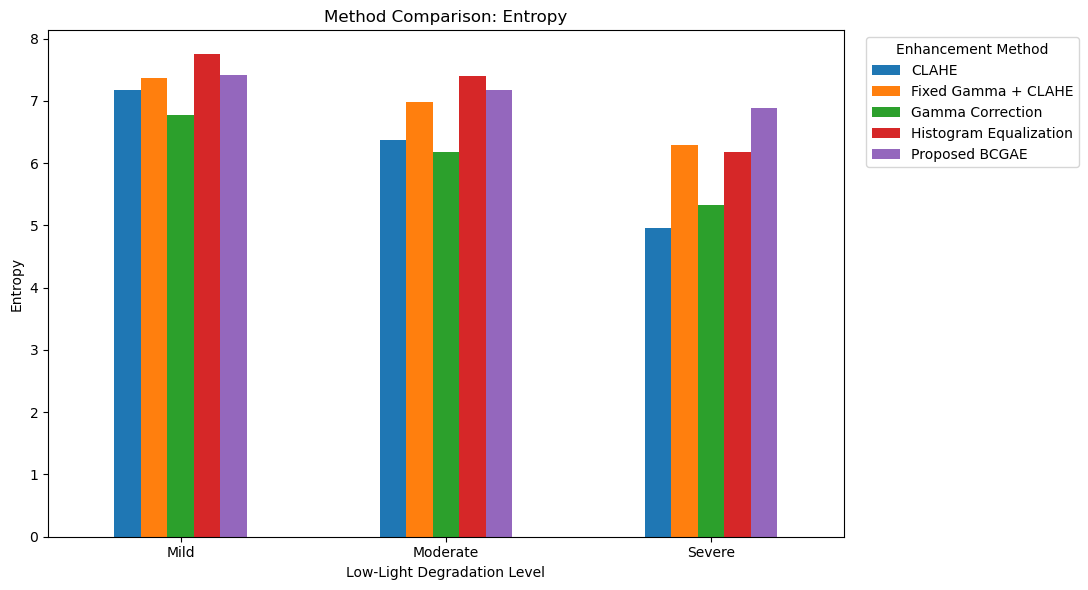

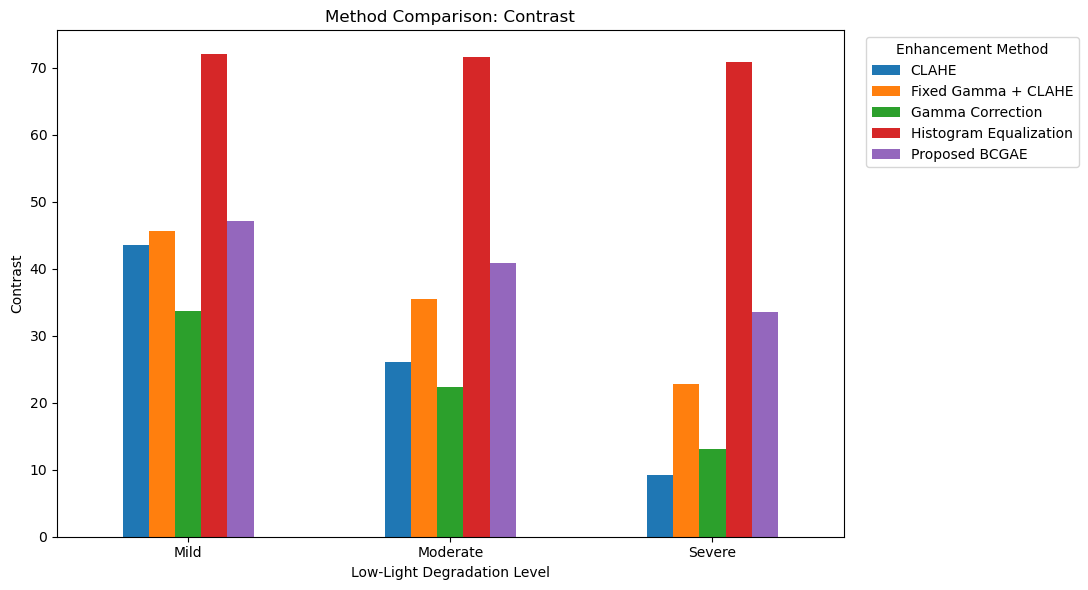

All five comparison graphs generated.
Graph folder: C:\Users\USER\Desktop\7th SEM\DIP\Project\Results\Graphs
Summary table: C:\Users\USER\Desktop\7th SEM\DIP\Project\Results\Graphs\mean_metrics_by_level.csv


In [21]:
import os
import pandas as pd
import matplotlib.pyplot as plt

# Load evaluation results
PROJECT_DIR = r"C:\Users\USER\Desktop\7th SEM\DIP\Project"
CSV_PATH = os.path.join(
    PROJECT_DIR, "Results", "evaluation_results.csv"
)

GRAPH_DIR = os.path.join(
    PROJECT_DIR, "Results", "Graphs"
)
os.makedirs(GRAPH_DIR, exist_ok=True)

df = pd.read_csv(CSV_PATH)

# Friendly labels for charts
method_labels = {
    "HE": "Histogram Equalization",
    "Gamma": "Gamma Correction",
    "CLAHE": "CLAHE",
    "Fixed_Gamma_CLAHE": "Fixed Gamma + CLAHE",
    "BCGAE": "Proposed BCGAE"
}

df["Method_Label"] = df["Method"].map(method_labels)

# Average metrics for each degradation level and method
metrics = ["MSE", "PSNR_dB", "SSIM", "Entropy", "Contrast"]

summary = (
    df.groupby(["Level", "Method_Label"])[metrics]
    .mean()
    .reset_index()
)

# Save summary table
summary_path = os.path.join(
    GRAPH_DIR, "mean_metrics_by_level.csv"
)
summary.to_csv(summary_path, index=False)

# Create one chart per metric
for metric in metrics:

    pivot = summary.pivot(
        index="Level",
        columns="Method_Label",
        values=metric
    )

    # Keep levels in experimental order
    pivot = pivot.reindex(["Mild", "Moderate", "Severe"])

    ax = pivot.plot(
        kind="bar",
        figsize=(11, 6)
    )

    ax.set_title(f"Method Comparison: {metric}")
    ax.set_xlabel("Low-Light Degradation Level")
    ax.set_ylabel(metric)
    ax.tick_params(axis="x", rotation=0)
    ax.legend(
        title="Enhancement Method",
        bbox_to_anchor=(1.02, 1),
        loc="upper left"
    )

    plt.tight_layout()

    output_path = os.path.join(
        GRAPH_DIR, f"{metric}_comparison.png"
    )

    plt.savefig(
        output_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

print("All five comparison graphs generated.")
print("Graph folder:", GRAPH_DIR)
print("Summary table:", summary_path)

In [22]:
import os
import time
import cv2
import numpy as np
import pandas as pd

PROJECT_DIR = r"C:\Users\USER\Desktop\7th SEM\DIP\Project"
LOW_LIGHT_DIR = os.path.join(PROJECT_DIR, "Images", "Low_Light")
RESULTS_DIR = os.path.join(PROJECT_DIR, "Results")

levels = ["Mild", "Moderate", "Severe"]

method_functions = {
    "HE": apply_he,
    "Gamma": lambda img: adjust_gamma(img, 0.60),
    "CLAHE": lambda img: apply_clahe(img, clip_limit=2.0),
    "Fixed_Gamma_CLAHE": lambda img: apply_clahe(
        adjust_gamma(img, 0.60), clip_limit=2.0
    ),
    "BCGAE": apply_bcgae
}

timing_records = []

for level in levels:
    input_dir = os.path.join(LOW_LIGHT_DIR, level)

    files = sorted([
        f for f in os.listdir(input_dir)
        if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp"))
    ])

    for filename in files:
        image = cv2.imread(os.path.join(input_dir, filename))

        if image is None:
            continue

        for method_name, function in method_functions.items():
            # Warm-up call, excluded from measurement
            function(image)

            # Average execution time over repeated runs
            repetitions = 5
            start = time.perf_counter()

            for _ in range(repetitions):
                function(image)

            elapsed = (time.perf_counter() - start) / repetitions

            timing_records.append({
                "Level": level,
                "Image": filename,
                "Method": method_name,
                "Time_ms": elapsed * 1000
            })

timing_df = pd.DataFrame(timing_records)

timing_summary = (
    timing_df.groupby("Method")["Time_ms"]
    .agg(["mean", "median", "std"])
    .reset_index()
    .rename(columns={
        "mean": "Mean_Time_ms",
        "median": "Median_Time_ms",
        "std": "Std_Time_ms"
    })
    .sort_values("Mean_Time_ms")
)

timing_df.to_csv(
    os.path.join(RESULTS_DIR, "individual_timing_results.csv"),
    index=False
)

timing_summary.to_csv(
    os.path.join(RESULTS_DIR, "timing_summary.csv"),
    index=False
)

display(timing_summary.round(3))

print("Timing results saved in:", RESULTS_DIR)

,Method,Mean_Time_ms,Median_Time_ms,Std_Time_ms
3,Gamma,0.544,0.308,0.631
4,HE,3.167,1.788,3.414
1,CLAHE,3.311,1.835,3.690
2,Fixed_Gamma_CLAHE,3.893,2.234,4.110
0,BCGAE,6.770,3.766,7.658


Timing results saved in: C:\Users\USER\Desktop\7th SEM\DIP\Project\Results


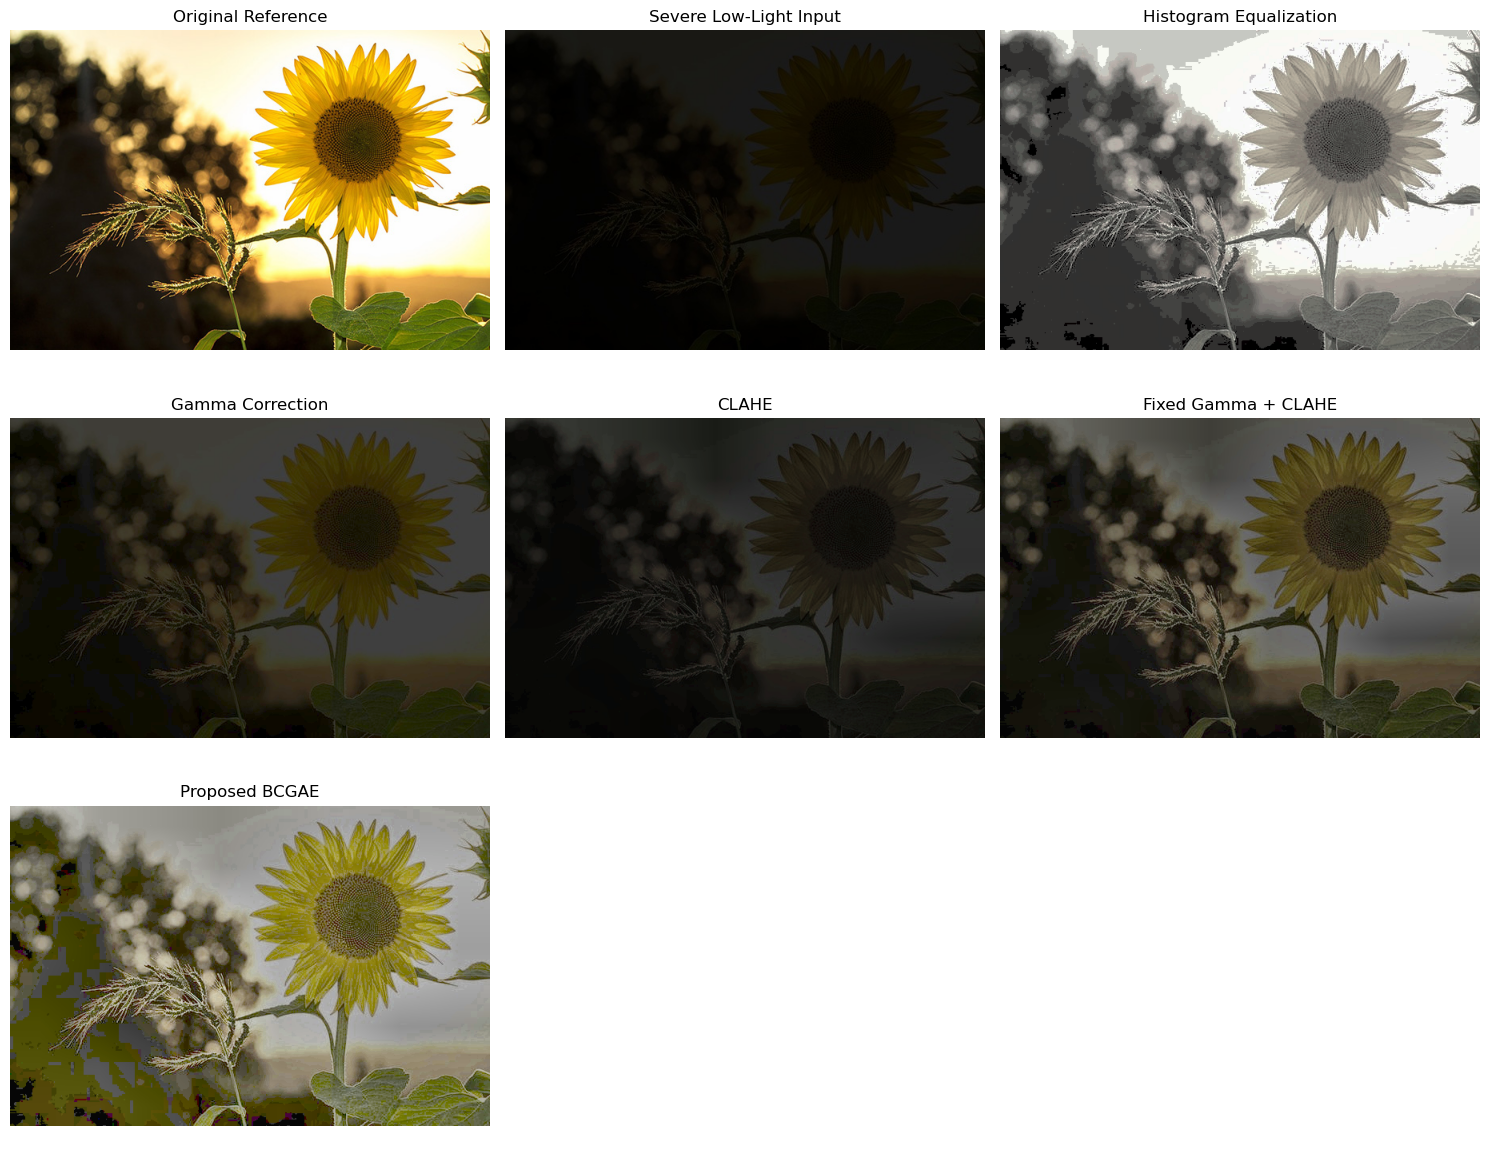

Visual comparison saved to: C:\Users\USER\Desktop\7th SEM\DIP\Project\Results\Graphs\severe_visual_comparison.png


In [23]:
import matplotlib.pyplot as plt

LEVEL = "Severe"

input_dir = os.path.join(LOW_LIGHT_DIR, LEVEL)
original_dir = os.path.join(PROJECT_DIR, "Images", "Original")

files = sorted([
    f for f in os.listdir(input_dir)
    if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp"))
])

# Select the first image for a reproducible example
filename = files[0]

low_light = cv2.imread(os.path.join(input_dir, filename))
original = cv2.imread(os.path.join(original_dir, filename))

if low_light is None or original is None:
    raise ValueError("Could not load the selected images.")

outputs = get_enhanced_images(low_light)

comparison = {
    "Original Reference": original,
    "Severe Low-Light Input": low_light,
    "Histogram Equalization": outputs["HE"],
    "Gamma Correction": outputs["Gamma"],
    "CLAHE": outputs["CLAHE"],
    "Fixed Gamma + CLAHE": outputs["Fixed_Gamma_CLAHE"],
    "Proposed BCGAE": outputs["BCGAE"]
}

fig, axes = plt.subplots(3, 3, figsize=(15, 12))
axes = axes.flatten()

for ax, (title, image) in zip(axes, comparison.items()):
    ax.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    ax.set_title(title)
    ax.axis("off")

# Hide two unused panels
for ax in axes[len(comparison):]:
    ax.axis("off")

plt.tight_layout()

figure_dir = os.path.join(RESULTS_DIR, "Graphs")
os.makedirs(figure_dir, exist_ok=True)

figure_path = os.path.join(
    figure_dir, "severe_visual_comparison.png"
)

plt.savefig(figure_path, dpi=300, bbox_inches="tight")
plt.show()

print("Visual comparison saved to:", figure_path)

In [13]:
import inspect

print("========== BCGAE IMPLEMENTATION ==========")
print(inspect.getsource(apply_bcgae))

print("\n========== GAMMA CORRECTION ==========")
print(inspect.getsource(adjust_gamma))

print("\n========== CLAHE IMPLEMENTATION ==========")
print(inspect.getsource(apply_clahe))

========== BCGAE IMPLEMENTATION ==========
def apply_bcgae(image):
    """
    Brightness and Contrast Guided Adaptive Enhancement.

    Gamma and CLAHE parameters are selected using
    measured brightness and contrast.

    These are initial heuristic rules and will need
    evaluation on the experimental dataset.
    """

    brightness, contrast = image_brightness_contrast(image)

    # Select gamma based on image brightness.
    if brightness < 60:
        gamma = 0.45
    elif brightness < 100:
        gamma = 0.60
    else:
        gamma = 0.75

    # Select CLAHE clip limit based on image contrast.
    if contrast < 35:
        clip_limit = 3.0
    elif contrast < 60:
        clip_limit = 2.0
    else:
        clip_limit = 1.5

    # First adjust brightness, then enhance local contrast.
    gamma_corrected = adjust_gamma(image, gamma)

    enhanced = apply_clahe(
        gamma_corrected,
        clip_limit=clip_limit
    )

    return enhanced


========== GAMMA CORRECTION ====

In [16]:
import os
import cv2

PROJECT_DIR = r"C:\Users\USER\Desktop\7th SEM\DIP\Project"

LOW_LIGHT_DIR = os.path.join(
    PROJECT_DIR, "Images", "Low_Light"
)

RESULTS_DIR = os.path.join(
    PROJECT_DIR, "Results", "Enhanced"
)

LEVELS = ["Mild", "Moderate", "Severe"]

for level in LEVELS:
    input_dir = os.path.join(LOW_LIGHT_DIR, level)
    output_dir = os.path.join(RESULTS_DIR, level, "BCGAE")

    os.makedirs(output_dir, exist_ok=True)

    files = [
        f for f in os.listdir(input_dir)
        if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp"))
    ]

    for filename in files:
        image = cv2.imread(os.path.join(input_dir, filename))

        if image is None:
            print("Skipped unreadable image:", filename)
            continue

        enhanced = apply_bcgae(image)

        output_path = os.path.join(output_dir, filename)

        if not cv2.imwrite(output_path, enhanced):
            print("Failed to save:", output_path)

    print(f"{level}: processed {len(files)} images")

print("Revised BCGAE outputs regenerated.")

Mild: processed 10 images
Moderate: processed 10 images
Severe: processed 10 images
Revised BCGAE outputs regenerated.


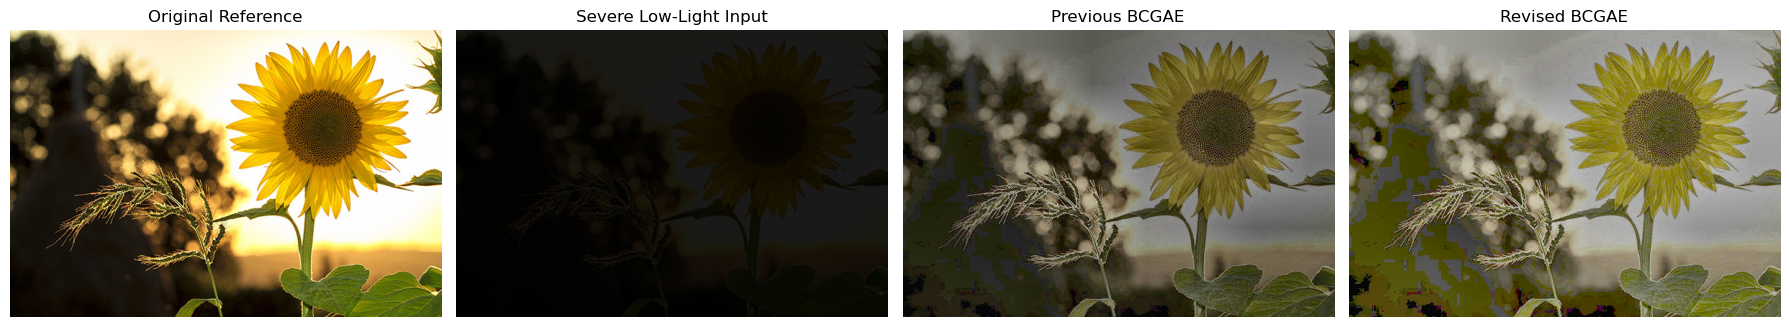

In [18]:
import os
import cv2
import matplotlib.pyplot as plt

PROJECT_DIR = r"C:\Users\USER\Desktop\7th SEM\DIP\Project"

filename = "IMG10_Sunflower.jpg"

original_path = os.path.join(
    PROJECT_DIR, "Images", "Original", filename
)

low_light_path = os.path.join(
    PROJECT_DIR, "Images", "Low_Light", "Severe", filename
)

original = cv2.imread(original_path)
low_light = cv2.imread(low_light_path)

if original is None or low_light is None:
    raise FileNotFoundError(
        "Check the sunflower filename and image folder paths."
    )

# Generate output using the revised function
revised_bcgae = apply_bcgae(low_light)

images = {
    "Original Reference": original,
    "Severe Low-Light Input": low_light,
    "Previous BCGAE": outputs["BCGAE"],
    "Revised BCGAE": revised_bcgae
}

fig, axes = plt.subplots(1, 4, figsize=(18, 5))

for ax, (title, image) in zip(axes, images.items()):
    ax.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [24]:
# Save all per-image enhancement comparisons for the DIP project
# Run this in the same notebook/session where apply_bcgae, adjust_gamma, apply_clahe exist.
# It saves one 6-panel comparison per input image, grouped by Mild/Moderate/Severe.
import os, cv2
import numpy as np
import matplotlib.pyplot as plt

PROJECT_DIR = r"C:\Users\USER\Desktop\7th SEM\DIP\Project"
LOW_LIGHT_DIR = os.path.join(PROJECT_DIR, "Images", "Low_Light")
ORIGINAL_DIR = os.path.join(PROJECT_DIR, "Images", "Original") # adjust if your originals are elsewhere
COMPARISON_DIR = os.path.join(PROJECT_DIR, "Results", "Visual_Comparisons")
os.makedirs(COMPARISON_DIR, exist_ok=True)

LEVELS = ["Mild", "Moderate", "Severe"]
EXTS = (".jpg", ".jpeg", ".png", ".bmp")

def he_color(image):
    # Standard histogram equalization on luminance, preserving color.
    lab = cv2.cvtColor(image, cv2.COLOR_BGR2LAB)
    l, a, b = cv2.split(lab)
    l2 = cv2.equalizeHist(l)
    return cv2.cvtColor(cv2.merge([l2, a, b]), cv2.COLOR_LAB2BGR)

def gamma_clahe_fixed(image, gamma=0.60, clip_limit=2.0):
    return apply_clahe(adjust_gamma(image, gamma), clip_limit=clip_limit)

def save_comparison(image, image_name, level, original=None):
    methods = [
        ("Low-Light Input", image),
        ("Histogram Equalization", he_color(image)),
        ("Gamma Correction", adjust_gamma(image, 0.60)),
        ("CLAHE", apply_clahe(image, clip_limit=2.0)),
        ("Fixed Gamma + CLAHE", gamma_clahe_fixed(image)),
        ("Proposed BCGAE", apply_bcgae(image)),
    ]
    if original is not None:
        methods.insert(0, ("Original Reference", original))
    n = len(methods)
    fig, axes = plt.subplots(2, (n+1)//2, figsize=(18, 8))
    axes = np.array(axes).reshape(-1)
    for ax, (title, im) in zip(axes, methods):
        ax.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))
        ax.set_title(title, fontsize=11)
        ax.axis("off")
    for ax in axes[len(methods):]:
        ax.axis("off")
    fig.suptitle(f"{level} — {image_name}", fontsize=14)
    fig.tight_layout()
    safe = os.path.splitext(image_name)[0]
    level_dir = os.path.join(COMPARISON_DIR, level)
    os.makedirs(level_dir, exist_ok=True)
    fig.savefig(os.path.join(level_dir, f"{safe}_comparison.png"), dpi=180, bbox_inches="tight")
    plt.close(fig)

for level in LEVELS:
    input_dir = os.path.join(LOW_LIGHT_DIR, level)
    if not os.path.isdir(input_dir):
        print("Missing input folder:", input_dir)
        continue
    for filename in sorted(os.listdir(input_dir)):
        if not filename.lower().endswith(EXTS):
            continue
        img = cv2.imread(os.path.join(input_dir, filename))
        if img is None:
            print("Skipped unreadable:", filename); continue
        # Set original_dir to the actual folder containing the matching clean image.
        original = None
        if os.path.isdir(ORIGINAL_DIR):
            candidate = os.path.join(ORIGINAL_DIR, filename)
            if os.path.exists(candidate):
                original = cv2.imread(candidate)
        save_comparison(img, filename, level, original)
    print("Saved comparisons for", level)
print("Done. Comparisons are in Results/Visual_Comparisons/")

Saved comparisons for Mild
Saved comparisons for Moderate
Saved comparisons for Severe
Done. Comparisons are in Results/Visual_Comparisons/


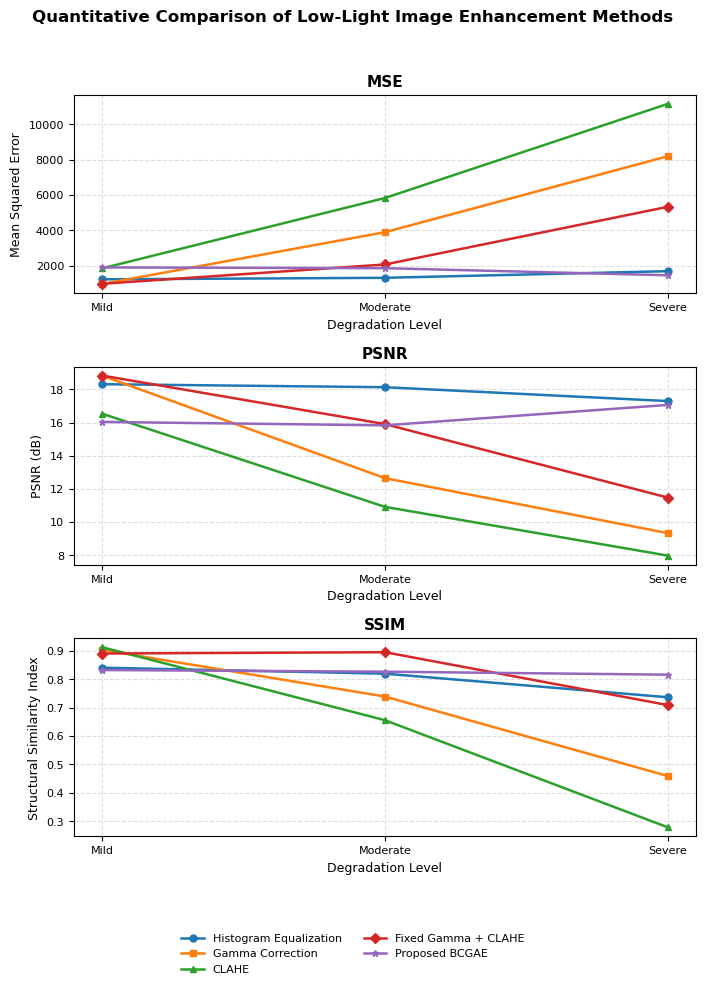

Saved successfully:
1. Fig2_Composite_MSE_PSNR_SSIM.png
2. Fig2_Composite_MSE_PSNR_SSIM.pdf


In [2]:
import matplotlib.pyplot as plt

# Three rows, one column
fig, axes = plt.subplots(3, 1, figsize=(7.16, 10))

metrics = [
    (mse, "MSE", "Mean Squared Error"),
    (psnr, "PSNR", "PSNR (dB)"),
    (ssim, "SSIM", "Structural Similarity Index")
]

markers = ["o", "s", "^", "D", "*"]

for ax, (data, title, ylabel) in zip(axes, metrics):

    for (method, values), marker in zip(data.items(), markers):
        ax.plot(
            levels,
            values,
            marker=marker,
            linewidth=1.8,
            markersize=5,
            label=method
        )

    ax.set_title(title, fontsize=11, fontweight="bold")
    ax.set_xlabel("Degradation Level", fontsize=9)
    ax.set_ylabel(ylabel, fontsize=9)
    ax.grid(True, linestyle="--", alpha=0.4)
    ax.tick_params(axis="both", labelsize=8)

# One shared legend at the bottom
handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="lower center",
    ncol=2,
    fontsize=8,
    frameon=False,
    bbox_to_anchor=(0.5, 0.005)
)

fig.suptitle(
    "Quantitative Comparison of Low-Light Image Enhancement Methods",
    fontsize=12,
    fontweight="bold"
)

plt.tight_layout(rect=[0, 0.10, 1, 0.96])

# Save the figure in the current working directory
plt.savefig(
    "Fig2_Composite_MSE_PSNR_SSIM.png",
    dpi=600,
    bbox_inches="tight"
)

# Also save as PDF for the IEEE report
plt.savefig(
    "Fig2_Composite_MSE_PSNR_SSIM.pdf",
    format="pdf",
    bbox_inches="tight"
)

plt.show()

print("Saved successfully:")
print("1. Fig2_Composite_MSE_PSNR_SSIM.png")
print("2. Fig2_Composite_MSE_PSNR_SSIM.pdf")

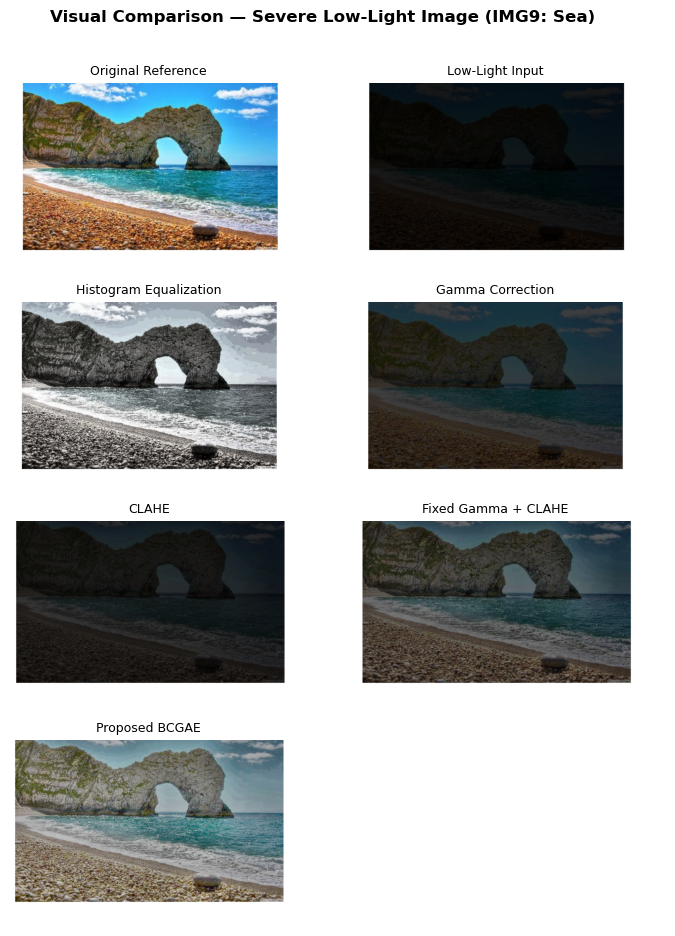

PNG saved: C:\Users\USER\Desktop\7th SEM\DIP\Project\Results\Visual_Comparisons\Severe\Fig1_IMG9_Sea_Visual_Comparison.png
PDF saved: C:\Users\USER\Desktop\7th SEM\DIP\Project\Results\Visual_Comparisons\Severe\Fig1_IMG9_Sea_Visual_Comparison.pdf


In [11]:
import matplotlib.pyplot as plt
import cv2
import os

# Path to the existing visual comparison image
input_path = r"C:\Users\USER\Desktop\7th SEM\DIP\Project\Results\Visual_Comparisons\Severe\IMG9_Sea_comparison.png"

output_dir = r"C:\Users\USER\Desktop\7th SEM\DIP\Project\Results\Visual_Comparisons\Severe"

# Read the comparison image
img = cv2.imread(input_path)

if img is None:
    raise FileNotFoundError(f"Image not found: {input_path}")

# Convert BGR to RGB
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

# The original montage has 7 panels, so split it into individual images.
# This code assumes the original montage is arranged as:
# 4 panels in row 1 and 3 panels in row 2.

h, w = img.shape[:2]

# Crop boundaries based on the montage layout
row1_y1, row1_y2 = int(h * 0.12), int(h * 0.52)
row2_y1, row2_y2 = int(h * 0.60), int(h * 0.98)

col_width = w // 4

panels = [
    img[row1_y1:row1_y2, int(i*w/4):int((i+1)*w/4)]
    for i in range(4)
]

panels += [
    img[row2_y1:row2_y2, int(i*w/4):int((i+1)*w/4)]
    for i in range(3)
]

titles = [
    "Original Reference",
    "Low-Light Input",
    "Histogram Equalization",
    "Gamma Correction",
    "CLAHE",
    "Fixed Gamma + CLAHE",
    "Proposed BCGAE"
]

# Create 4 rows × 2 columns
fig, axes = plt.subplots(4, 2, figsize=(7.16, 9.5))
axes = axes.flatten()

for i, (panel, title) in enumerate(zip(panels, titles)):
    axes[i].imshow(panel)
    axes[i].set_title(title, fontsize=9)
    axes[i].axis("off")

# Hide the unused eighth cell
axes[7].axis("off")

fig.suptitle(
    "Visual Comparison — Severe Low-Light Image (IMG9: Sea)",
    fontsize=12,
    fontweight="bold"
)

plt.tight_layout(rect=[0, 0, 1, 0.97])

# Save both files to your Windows folder
output_png = os.path.join(output_dir, "Fig1_IMG9_Sea_Visual_Comparison.png")
output_pdf = os.path.join(output_dir, "Fig1_IMG9_Sea_Visual_Comparison.pdf")

fig.savefig(output_png, dpi=600, bbox_inches="tight")
fig.savefig(output_pdf, format="pdf", bbox_inches="tight")

plt.show()

print("PNG saved:", output_png)
print("PDF saved:", output_pdf)

In [7]:
import os

print("Current working directory:", os.getcwd())
print("Files in current directory:", os.listdir())

Current working directory: C:\Users\USER\Desktop\7th SEM\DIP\Project
Files in current directory: ['.ipynb_checkpoints', 'BCGAE_Low_Light_Enhancement.ipynb', 'conference-template-a4 (1) (1).docx', 'Fig2_Composite_MSE_PSNR_SSIM.pdf', 'Fig2_Composite_MSE_PSNR_SSIM.png', 'Images', 'Paper.docx', 'PPT.pptx', 'Results']


In [8]:
import os

for root, dirs, files in os.walk(os.getcwd()):
    for file in files:
        if "IMG9_Sea" in file or "Sea_comparison" in file:
            print(os.path.join(root, file))

C:\Users\USER\Desktop\7th SEM\DIP\Project\Images\Low_Light\Mild\IMG9_Sea.jpg
C:\Users\USER\Desktop\7th SEM\DIP\Project\Images\Low_Light\Moderate\IMG9_Sea.jpg
C:\Users\USER\Desktop\7th SEM\DIP\Project\Images\Low_Light\Severe\IMG9_Sea.jpg
C:\Users\USER\Desktop\7th SEM\DIP\Project\Images\Original\IMG9_Sea.jpg
C:\Users\USER\Desktop\7th SEM\DIP\Project\Results\Enhanced\Mild\BCGAE\IMG9_Sea.jpg
C:\Users\USER\Desktop\7th SEM\DIP\Project\Results\Enhanced\Mild\CLAHE\IMG9_Sea.jpg
C:\Users\USER\Desktop\7th SEM\DIP\Project\Results\Enhanced\Mild\Fixed_Gamma_CLAHE\IMG9_Sea.jpg
C:\Users\USER\Desktop\7th SEM\DIP\Project\Results\Enhanced\Mild\Gamma\IMG9_Sea.jpg
C:\Users\USER\Desktop\7th SEM\DIP\Project\Results\Enhanced\Mild\HE\IMG9_Sea.jpg
C:\Users\USER\Desktop\7th SEM\DIP\Project\Results\Enhanced\Moderate\BCGAE\IMG9_Sea.jpg
C:\Users\USER\Desktop\7th SEM\DIP\Project\Results\Enhanced\Moderate\CLAHE\IMG9_Sea.jpg
C:\Users\USER\Desktop\7th SEM\DIP\Project\Results\Enhanced\Moderate\Fixed_Gamma_CLAHE\IMG9_Sea